In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")

print("Path to dataset files:", path)

Path to dataset files: /home/chris/.cache/kagglehub/datasets/jessemostipak/hotel-booking-demand/versions/1


In [64]:
import pandas as pd
import numpy as np
df = pd.read_csv(f'{path}/hotel_bookings.csv')

In [65]:
df = df.drop_duplicates()

In [66]:
df.shape

(87396, 32)

In [67]:
with pd.option_context('display.max_columns', None):
    display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [68]:
df = df.drop(columns = ['reservation_status', 'reservation_status_date'])

In [69]:
for col in ['agent', 'company']:
    df[f'has_{col}'] = df[col].notna().astype(int)
    df[col] = df[col].apply(lambda v: 'none' if pd.isna(v) else str(int(v)))

In [70]:
with pd.option_context('display.max_columns', None):
    display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_agent,has_company
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,none,none,0,Transient,0.0,0,0,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,none,none,0,Transient,0.0,0,0,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,none,none,0,Transient,75.0,0,0,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304,none,0,Transient,75.0,0,0,1,0
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240,none,0,Transient,98.0,0,1,1,0


In [71]:
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('unknown')

In [72]:
# no nulls after this point

In [73]:
cols = ['reserved_room_type', 'assigned_room_type']
df['got_room'] = np.where(df['reserved_room_type'] == df['assigned_room_type'], 1, 0)

In [74]:
df = df.drop(columns = cols)

In [75]:
import calendar
months = {m: i for i, m in enumerate(calendar.month_name) if m}

df['arrival_date'] = pd.to_datetime(dict(
    year=df['arrival_date_year'],
    month=df['arrival_date_month'].map(months),
    day=df['arrival_date_day_of_month'],
))

df['arrival_month'] = df['arrival_date'].dt.month
df['arrival_dow']   = df['arrival_date'].dt.dayofweek
df['is_weekend']    = (df['arrival_dow'] >= 5).astype(int)

df['month_sin'] = np.sin(2 * np.pi * df['arrival_month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['arrival_month'] / 12)

In [76]:
df = df.drop(columns=['arrival_date_year', 'arrival_date_month',
                      'arrival_date_week_number', 'arrival_date_day_of_month'])

In [77]:
df.shape

(87396, 33)

In [78]:
from sklearn.model_selection import train_test_split
df = df.sort_values('arrival_date').reset_index(drop=True)
X = df.drop(columns = 'is_canceled')
y = df['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state =42,
    shuffle = False)
X_train = X_train.drop(columns = 'arrival_date')
X_test = X_test.drop(columns = 'arrival_date')


In [79]:
from sklearn.preprocessing import OneHotEncoder

special_encoder = OneHotEncoder(handle_unknown='ignore', min_frequency=300, sparse_output=False)
special_encoder.set_output(transform='pandas')
special_cols = ['country', 'agent', 'company']

encoded_cols = special_encoder.fit_transform(X_train[special_cols])

X_train = pd.concat([X_train.drop(columns=special_cols), encoded_cols], axis=1)
encoded_cols = special_encoder.transform(X_test[special_cols])
X_test = pd.concat([X_test.drop(columns = special_cols), encoded_cols], axis=1)


In [80]:
# df['country'].value_counts().loc[lambda x: x > 100]
# df.head()
encoder = OneHotEncoder(handle_unknown = 'ignore', sparse_output=False)
encoder.set_output(transform='pandas')
cols = ['hotel', 'meal', 'distribution_channel', 'market_segment', 'deposit_type', 'customer_type', 'arrival_dow']

encoded_cols = encoder.fit_transform(X_train[cols])

X_train = pd.concat([X_train.drop(columns = cols), encoded_cols], axis = 1)
X_train = X_train.drop(columns = 'arrival_month')

encoded_cols = encoder.transform(X_test[cols])

X_test = pd.concat([X_test.drop(columns = cols), encoded_cols], axis = 1)
X_test = X_test.drop(columns = 'arrival_month')

In [81]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
numeric_cols = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights' ,'adults' ,
                'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled' , 'booking_changes',
                'days_in_waiting_list', 'adr' ,'total_of_special_requests' ,'required_car_parking_spaces']



In [82]:
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train_scaled[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test_scaled[numeric_cols])

In [83]:
X_train_scaled.head()


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,...,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,arrival_dow_0,arrival_dow_1,arrival_dow_2,arrival_dow_3,arrival_dow_4,arrival_dow_5,arrival_dow_6
0,3.421504,-0.953135,-1.242962,0.220548,-0.289226,-0.09634,0,-0.086325,-0.112462,3.802673,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.311529,2.910464,4.069247,0.220548,-0.289226,-0.09634,0,-0.086325,-0.112462,-0.374484,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.324120,0.978665,2.620463,0.220548,-0.289226,-0.09634,0,-0.086325,-0.112462,-0.374484,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.834252,-0.953135,-0.760034,-1.304056,-0.289226,-0.09634,0,-0.086325,2.360344,-0.374484,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,2.351269,-0.953135,-0.277106,0.220548,-0.289226,-0.09634,0,2.427421,-0.112462,-0.374484,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [84]:
X_train_scaled.shape

(69916, 105)

In [86]:
X_test_scaled.shape

(17480, 105)

In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(random_state=42, max_iter = 300)
model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)
probabilities = model.predict_proba(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test, predictions):.2%}")

Accuracy: 76.08%


In [88]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components = 1, random_state = 42)
X_reduced_train = svd.fit_transform(X_train_scaled)
X_reduced_test = svd.transform(X_test_scaled)

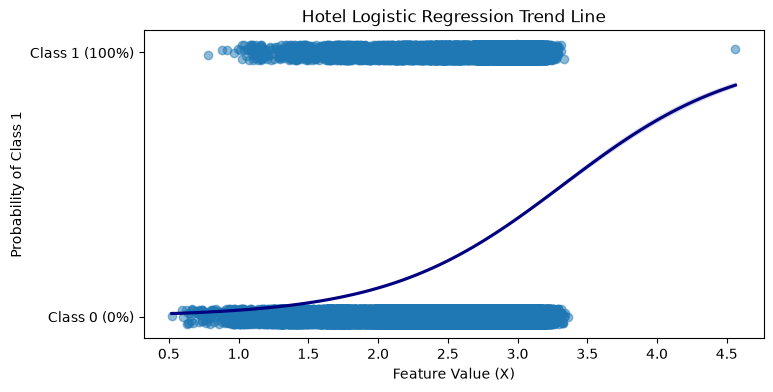

<Figure size 640x480 with 0 Axes>

In [94]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.figure(figsize=(8, 4))
# sns.regplot automatically handles the logistic curve fitting
sns.regplot(x=X_reduced_train, y=y_train, logistic=True, y_jitter=0.03, 
            scatter_kws={'alpha':0.5}, line_kws={'color':'navy'})

plt.yticks([0, 1], ['Class 0 (0%)', 'Class 1 (100%)'])
plt.xlabel('Feature Value (X)')
plt.ylabel('Probability of Class 1')
plt.title('Hotel Logistic Regression Trend Line')
plt.show()
plt.savefig('hotel.png')


<Figure size 640x480 with 0 Axes>